In [9]:
#1、Significant earthquakes since 2150 B.C
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

Sig_Eqs = pd.read_csv(r"earthquakes-2026-10-14_11-23-28_+0800.tsv", sep="\t")
Sig_Eqs.head()

,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
0,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1.0,-2150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2.0,-2000.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,3.0,-2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
4,NaN,5877.0,-1610.0,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN


In [10]:
#1、1
country=Sig_Eqs.groupby(['Country'])['Deaths'].sum().sort_values(ascending=False)
country.head(20)

Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014453.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64

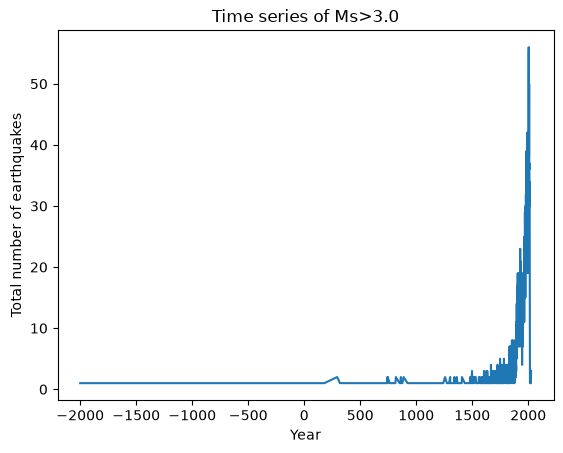

In [11]:
#1、2
total_number=Sig_Eqs.loc[Sig_Eqs['Ms']>3.0].groupby(['Year'])['Ms'].count().plot(kind='line')
plt.xlabel('Year')
plt.ylabel('Total number of earthquakes')
plt.title('Time series of Ms>3.0')
plt.show()

In [13]:
#1.3
def CountEq_LargestEq(country):
    data=Sig_Eqs.loc[Sig_Eqs['Country']==country]
    total_number=len(data)
    max=data.sort_values(by='Ms', ascending=False).head(1)
    year=max['Year'].iloc[0]
    location=max['Location Name'].iloc[0]
    return  total_number,year,location
CountEq_LargestEq('CHINA')


countries=Sig_Eqs['Country'].dropna().unique()
result=pd.DataFrame(columns=['Country', 'Total_number', 'Year', 'Location'])
for x in countries:
    total_number,year,location=CountEq_LargestEq(x)
    new=pd.DataFrame([{'Country': x,'Total_number':total_number,'Year':year,'Location':location}])
    result=pd.concat([result, new]).reset_index(drop=True).sort_values(by='Total_number', ascending=False)
result.head(10)


,Country,Total_number,Year,Location
0,CHINA,626,1920.0,"CHINA: GANSU PROVINCE, SHANXI PROVINCE"
1,JAPAN,429,869.0,JAPAN: SANRIKU
2,INDONESIA,427,2004.0,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
3,IRAN,385,856.0,"IRAN: DAMGHAN, QUMIS"
4,TURKEY,359,1999.0,"TURKEY: ISTANBUL, KOCAELI, SAKARYA"
5,ITALY,338,1915.0,"ITALY: MARSICA, AVEZZANO, ABRUZZI"
6,GREECE,296,365.0,GREECE: CRETE: KNOSSOS
7,USA,283,1957.0,ALASKA
8,PHILIPPINES,233,1897.0,"PHILIPPINES: MINDANAO, ZAMBOANGA, SULU, ISABELA"
9,MEXICO,217,1787.0,"MEXICO: SAN MARCOS, OAXACA"


C:\Users\23143\AppData\Local\Temp\ipykernel_22824\1187979010.py:7: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  temp=pd.read_csv("Baoan_Weather_1998_2022.csv")


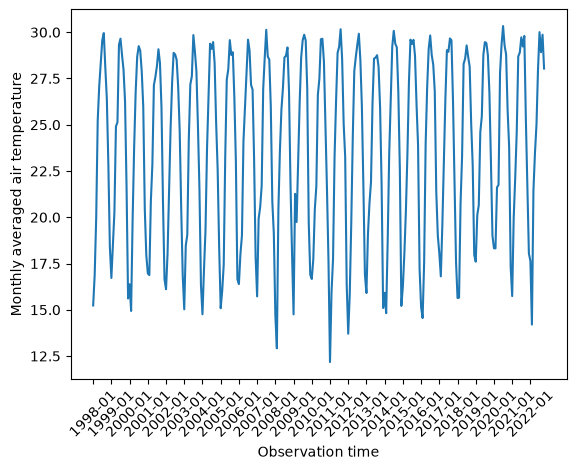

In [1]:
#2、Air temperature in Shenzhen 1998-2022

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

temp=pd.read_csv("Baoan_Weather_1998_2022.csv")
temp['TMP'] =temp[temp['TMP']!=+9999]['TMP'].str[0:5].astype(float)/10
temp = temp[(temp['TMP']>=-93.2)&(temp['TMP']<= 61.8)]
temp['TMP']
temp['month']=temp['DATE'].str[0:7]
mtemp=temp.groupby('month')['TMP'].mean()

plt.plot(mtemp.index, mtemp.values)
plt.xlabel('Observation time')
plt.ylabel('Monthly averaged air temperature') 
plt.xticks(ticks=mtemp.index[::12],rotation=45) 
plt.show()

In [28]:
#3. Global collection of hurricanes

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])
df.head()

C:\Users\23143\AppData\Local\Temp\ipykernel_3816\2873963242.py:7: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___
4,1842298N11080,1842,1,NI,AS,NaN,1842-10-25 18:00:00,NR,10.7884,77.9194,,,,main,0,0,__________P___


In [29]:
#3.1
df.groupby(['SID','NAME'])['WMO_WIND'].max().sort_values( ascending=False).head(10)

SID            NAME   
1950224N17305  ABLE       95
1950234N11334  CHARLIE    95
1950244N20277  EASY       95
1950251N16319  FOX        95
1950270N25309  GEORGE     95
1951224N12316  CHARLIE    95
1951244N13328  EASY       95
1951246N13340  FOX        95
1952244N15306  BAKER      95
1952268N20291  CHARLIE    95
Name: WMO_WIND, dtype: str

In [13]:
#3.2
df['WMO_WIND'].sort_values( ascending=False).head(20)

46787    95
46789    95
46791    95
46815    95
46817    95
46819    95
46821    95
46823    95
46942    95
46952    95
47532    95
49333    95
49375    95
49450    95
49466    95
52446    95
52448    95
52450    95
52452    95
52454    95
Name: WMO_WIND, dtype: str

In [15]:
#3.3
df.groupby(['BASIN'])['BASIN'].count()

BASIN
EP     62412
NI     55401
SA       119
SI    160668
SP     67119
WP    236576
Name: BASIN, dtype: int64

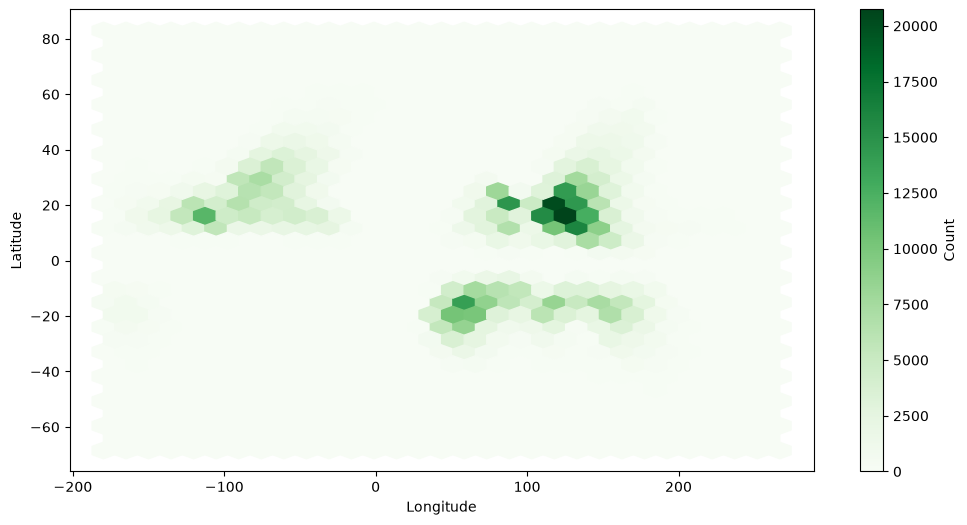

In [30]:
#3.4
plt.figure(figsize=(12, 6))
plt.hexbin(df['LON'],df['LAT'],gridsize=30, cmap='Greens') 
plt.colorbar(label='Count')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

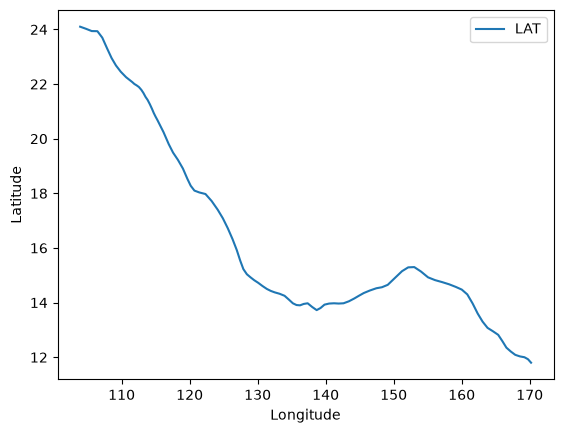

In [35]:
#3.5
df[(df['NAME']=='MANGKHUT')&(df['ISO_TIME'].dt.year==2018)].plot(x='LON', y='LAT')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [32]:
#3.6
data=df[(df['ISO_TIME'].dt.year>=1970) & ((df['BASIN']=='WP') | (df['BASIN']=='EP'))]
data

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350393,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,,1006,tokyo,main,1088,1088,_OO___________
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,,,,main,1109,1109,_PP___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,,1002,tokyo,main,1143,1143,_OO___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,,,,main,1171,1168,_PP___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,,998,tokyo,main,1182,1179,_OO___________
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
707084,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 15:00:00,TS,13.99570,-90.294,,,,PROVISIONAL,0,0,P_____________
707085,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 18:00:00,NR,14.50000,-91.000,,,,PROVISIONAL,0,,O_____________
707173,2022286N15151,2022,80,WP,MM,NaN,2022-10-12 12:00:00,NR,15.20000,151.300,,,,PROVISIONAL,1985,1974,O_____________
707174,2022286N15151,2022,80,WP,MM,NaN,2022-10-12 15:00:00,NR,15.05000,151.325,,,,PROVISIONAL,1974,1952,P_____________


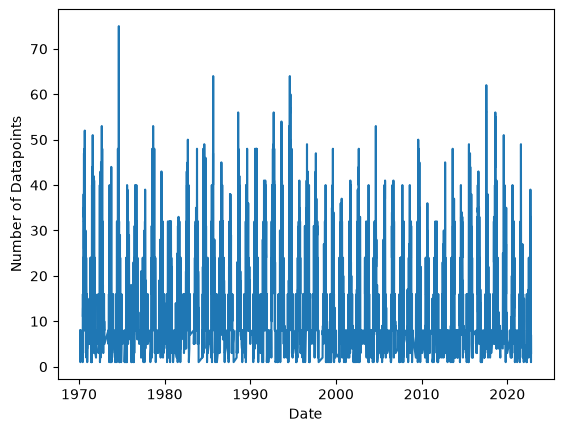

In [33]:
#3.7
%matplotlib inline
data.groupby(data['ISO_TIME'].dt.date).size().plot()
plt.xlabel('Date')
plt.ylabel('Number of Datapoints')
plt.show()

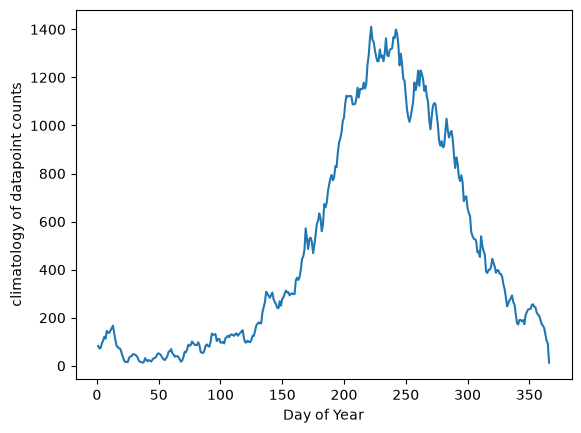

In [34]:
#3.8
data['day_of_year']=data['ISO_TIME'].dt.dayofyear
climatology=data.groupby('day_of_year').size() 
climatology.plot()
plt.xlabel('Day of Year')
plt.ylabel('climatology of datapoint counts')
plt.show()

In [35]:
#3.9
daily_counts = data.groupby(data['ISO_TIME'].dt.date).size()
years=data['ISO_TIME'].dt.year.nunique()
climatology_mean=climatology/years
day_of_year=pd.to_datetime(daily_counts.index).dayofyear
anomaly=daily_counts-climatology_mean.loc[day_of_year].values
anomaly.head()

ISO_TIME
1970-02-19    7.018868
1970-02-20    7.094340
1970-02-21    7.188679
1970-02-22    7.377358
1970-02-23    7.490566
dtype: float64

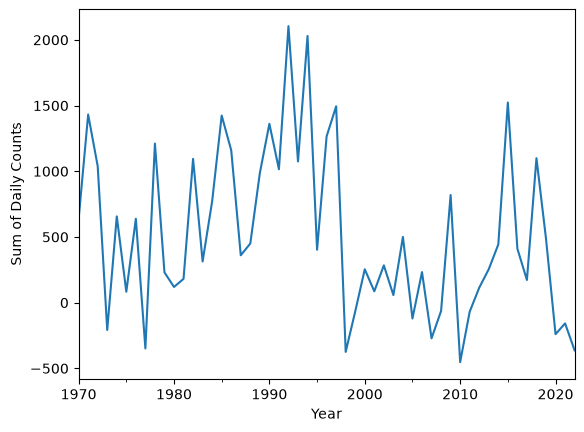

In [38]:
#3.10
anomaly.index = pd.to_datetime(anomaly.index)
SumCounts = anomaly.resample('YE').sum() 
SumCounts.plot()
plt.xlabel('Year')
plt.ylabel('Sum of Daily Counts')
plt.show()

In [33]:
SumCounts.sort_values(ascending=False).head(10)

ISO_TIME
1992    1674.603774
1994    1624.849057
1997    1228.849057
1990    1134.849057
2015    1132.849057
1971    1131.849057
1985     951.849057
1996     904.603774
1993     813.849057
1986     808.849057
dtype: float64

In [35]:
SumCounts.sort_values().head(10)

ISO_TIME
2010   -1655.150943
1998   -1020.150943
2021    -991.150943
2007    -922.150943
1973    -920.150943
1977    -886.150943
1999    -872.150943
2020    -841.396226
2022    -794.981132
2011    -742.150943
dtype: float64

In [2]:
#4、Explore a data set

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [3]:
#4.1

welldata=pd.read_excel('WZ1.xlsx')
welldata.head(10)

,序号,站点编号,监测时间,均一化浊度,均一化水位
0,1,WZ1,2023-04-07 15:00:00,1.138439,1.010101
1,2,WZ1,2023-04-07 16:00:00,1.138439,1.010101
2,3,WZ1,2023-04-07 20:00:00,1.094035,1.008931
3,4,WZ1,2023-04-07 21:00:00,1.120315,1.006593
4,5,WZ1,2023-04-07 22:00:00,1.120315,1.006593
5,6,WZ1,2023-04-08 03:00:00,1.062430,1.006593
6,7,WZ1,2023-04-08 04:00:00,1.062430,1.006593
7,8,WZ1,2023-04-08 05:00:00,1.063789,1.005424
8,9,WZ1,2023-04-08 06:00:00,1.063789,1.005424
9,10,WZ1,2023-04-08 07:00:00,1.063789,1.005424


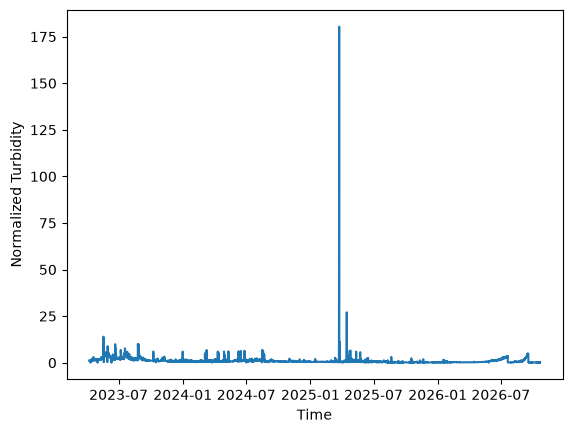

In [4]:
#4.2 选择均一化浊度

plt.plot(welldata['监测时间'], welldata['均一化浊度'])
plt.xlabel('Time')
plt.ylabel('Normalized Turbidity')
plt.show()

In [5]:
#4.3.1基础特征
welldata['均一化浊度'].describe()

count    26675.000000
mean         1.000000
std          3.754472
min          0.014567
25%          0.303527
50%          0.598105
75%          1.008397
max        180.337855
Name: 均一化浊度, dtype: float64

In [7]:
#4.3.2最大值出现的时间
welldata['均一化浊度'].max()
welldata.loc[welldata['均一化浊度'].idxmax(), '监测时间']

Timestamp('2025-03-24 09:00:00')

In [10]:
#4.3.3最小值出现的时间
welldata['均一化浊度'].min()
welldata.loc[welldata['均一化浊度'].idxmin(), '监测时间']

Timestamp('2025-10-15 16:00:00')

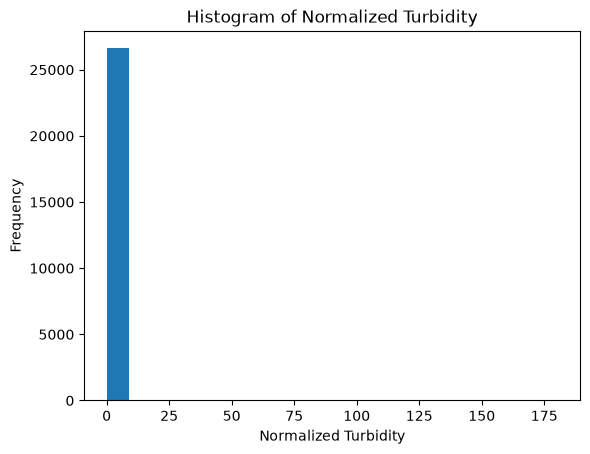

In [23]:
#4.3.4直方图
welldata['均一化浊度'].plot(kind='hist', bins=20)
plt.xlabel('Normalized Turbidity')
plt.title('Histogram of Normalized Turbidity')
plt.show()

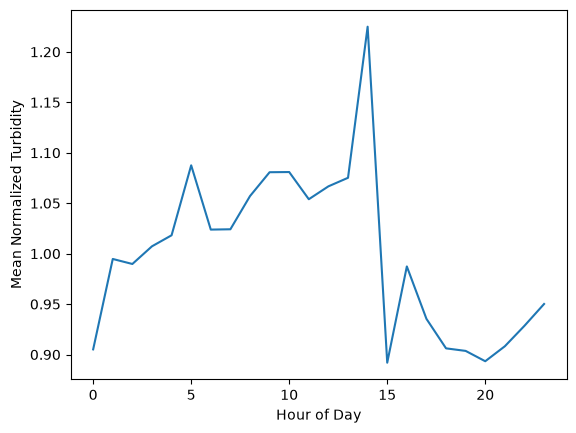

In [22]:
#4.3.5按小时计算平均浊度
welldata['Hour'] = welldata['监测时间'].dt.hour
welldata.groupby('Hour')['均一化浊度'].mean().plot()
plt.xlabel('Hour of Day')
plt.ylabel('Mean Normalized Turbidity')
plt.show()